# Лабораторна робота №3
## Тема: Розвідувальний (дослідницький) аналіз даних (EDA)
**Дисципліна:** Методи та технології інженерії даних  
**Студент:** Чепара Станіслав (група ФеП-32)  
**Викладач:** асистент кафедри системного проєктування Фостяк М. Р.  
**Навчальний заклад:** Львівський національний університет імені Івана Франка, факультет електроніки та комп'ютерних технологій  

---

### Мета роботи
Набути практичних навичок побудови послідовного процесу розвідувального аналізу даних (EDA); дослідити структуру та якість набору даних `Automobile_data.csv`; виконати всебічний одновимірний, двовимірний та кореляційний аналіз; перевірити розподіли на нормальність; виявити та обґрунтувати природу викидів; сформувати аналітичні рекомендації для побудови Data Engineering pipeline.

## 1. Загальна постановка завдання та імпорт бібліотек
Завантажуємо необхідні бібліотеки для обробки даних, статистичного аналізу та побудови графіків. Налаштовуємо стилі візуалізації.

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Налаштування формату відображення
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

## 2. Завантаження та первинне дослідження даних (Data Understanding)
Завантажуємо датасет у DataFrame, оцінюємо розмірність, назви колонок, перші та останні записи, типи даних та обсяг оперативної пам'яті.

In [2]:
# Завантаження вихідного файлу
raw_df = pd.read_csv("Automobile_data.csv")
print(f"Розмір набору даних (рядків, колонок): {raw_df.shape}")
print(f"Обсяг пам'яті: {raw_df.memory_usage(deep=True).sum() / 1024:.2f} KB")

Розмір набору даних (рядків, колонок): (205, 26)
Обсяг пам'яті: 185.73 KB


In [3]:
# Перші 10 записів
raw_df.head(10)

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.60,168.80,64.10,48.80,2548,dohc,four,130,mpfi,3.47,2.68,9.00,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.60,168.80,64.10,48.80,2548,dohc,four,130,mpfi,3.47,2.68,9.00,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.50,171.20,65.50,52.40,2823,ohcv,six,152,mpfi,2.68,3.47,9.00,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.80,176.60,66.20,54.30,2337,ohc,four,109,mpfi,3.19,3.4,10.00,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.40,176.60,66.40,54.30,2824,ohc,five,136,mpfi,3.19,3.4,8.00,115,5500,18,22,17450
5,2,?,audi,gas,std,two,sedan,fwd,front,99.80,177.30,66.30,53.10,2507,ohc,five,136,mpfi,3.19,3.4,8.50,110,5500,19,25,15250
6,1,158,audi,gas,std,four,sedan,fwd,front,105.80,192.70,71.40,55.70,2844,ohc,five,136,mpfi,3.19,3.4,8.50,110,5500,19,25,17710
7,1,?,audi,gas,std,four,wagon,fwd,front,105.80,192.70,71.40,55.70,2954,ohc,five,136,mpfi,3.19,3.4,8.50,110,5500,19,25,18920
8,1,158,audi,gas,turbo,four,sedan,fwd,front,105.80,192.70,71.40,55.90,3086,ohc,five,131,mpfi,3.13,3.4,8.30,140,5500,17,20,23875
9,0,?,audi,gas,turbo,two,hatchback,4wd,front,99.50,178.20,67.90,52.00,3053,ohc,five,131,mpfi,3.13,3.4,7.00,160,5500,16,22,?


In [4]:
# Останні 10 записів
raw_df.tail(10)

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
195,-1,74,volvo,gas,std,four,wagon,rwd,front,104.30,188.80,67.20,57.50,3034,ohc,four,141,mpfi,3.78,3.15,9.50,114,5400,23,28,13415
196,-2,103,volvo,gas,std,four,sedan,rwd,front,104.30,188.80,67.20,56.20,2935,ohc,four,141,mpfi,3.78,3.15,9.50,114,5400,24,28,15985
197,-1,74,volvo,gas,std,four,wagon,rwd,front,104.30,188.80,67.20,57.50,3042,ohc,four,141,mpfi,3.78,3.15,9.50,114,5400,24,28,16515
198,-2,103,volvo,gas,turbo,four,sedan,rwd,front,104.30,188.80,67.20,56.20,3045,ohc,four,130,mpfi,3.62,3.15,7.50,162,5100,17,22,18420
199,-1,74,volvo,gas,turbo,four,wagon,rwd,front,104.30,188.80,67.20,57.50,3157,ohc,four,130,mpfi,3.62,3.15,7.50,162,5100,17,22,18950
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.10,188.80,68.90,55.50,2952,ohc,four,141,mpfi,3.78,3.15,9.50,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.10,188.80,68.80,55.50,3049,ohc,four,141,mpfi,3.78,3.15,8.70,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.10,188.80,68.90,55.50,3012,ohcv,six,173,mpfi,3.58,2.87,8.80,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.10,188.80,68.90,55.50,3217,ohc,six,145,idi,3.01,3.4,23.00,106,4800,26,27,22470
204,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.10,188.80,68.90,55.50,3062,ohc,four,141,mpfi,3.78,3.15,9.50,114,5400,19,25,22625


In [5]:
# Загальна інформація про типи та непустий вміст
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    str    
 2   make               205 non-null    str    
 3   fuel-type          205 non-null    str    
 4   aspiration         205 non-null    str    
 5   num-of-doors       205 non-null    str    
 6   body-style         205 non-null    str    
 7   drive-wheels       205 non-null    str    
 8   engine-location    205 non-null    str    
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    str    
 15  num-of-cylinders   205 non-null    str    
 16  engine-size        205 non-null    in

In [6]:
# Кількість унікальних значень для кожної ознаки
raw_df.nunique()

symboling              6
normalized-losses     52
make                  22
fuel-type              2
aspiration             2
num-of-doors           3
body-style             5
drive-wheels           3
engine-location        2
wheel-base            53
length                75
width                 44
height                49
curb-weight          171
engine-type            7
num-of-cylinders       7
engine-size           44
fuel-system            8
bore                  39
stroke                37
compression-ratio     32
horsepower            60
peak-rpm              24
city-mpg              29
highway-mpg           30
price                187
dtype: int64

**Короткий висновок про структуру набору даних:**
Датасет містить 205 спостережень та 26 ознак. Ознаки описують технічні параметри автомобілів (габарити, об'єм і тип двигуна, потужність, витрату пального), категорійні атрибути (марка, кузов, тип приводу), а також ціну та страховий рейтинг ризику (`symboling`). Значна частина числових характеристик має тип `object` через використання символу `'?'` замість пропущених значень.

## 3. Класифікація ознак
Розподіляємо ознаки на семантичні категорії з урахуванням змісту показників, а не лише їх технічного `dtype` у pandas.

In [7]:
numeric_columns = [
    'symboling', 'normalized-losses', 'wheel-base', 'length', 'width', 'height',
    'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio',
    'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price'
]

categorical_columns = [
    'make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style',
    'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system'
]

datetime_columns = []  # Ознаки дат/часу відсутні в наборі
id_columns = []        # Унікальний технічний ідентифікатор відсутній (ідентифікація за індексом рядка)

print(f"Числових ознак: {len(numeric_columns)}")
print(f"Категорійних ознак: {len(categorical_columns)}")

Числових ознак: 16
Категорійних ознак: 10


**Обґрунтування вибору типів для неоднозначних ознак:**
1. `symboling`: цілочисельний страховий рейтинг від -3 до +3. Семантично це порядкова ознака або дискретна числова шкала. У межах EDA розглядається як числова для аналізу статистик, але в моделюванні може вимагати порядкового кодування.
2. `normalized-losses`: неперервна числова величина (відносний страховий збиток), яка отримала тип `object` виключно через наявність рядкового маркера пропуску `'?'`.
3. `num-of-doors` та `num-of-cylinders`: містять текстові значення ("two", "four", "six" тощо). Семантично це дискретні числові величини, проте в поточному стані вони класифіковані як категорійні (порядкові).
4. `bore`, `stroke`, `horsepower`, `peak-rpm`, `price`: фізичні неперервні параметри та ціна, що є строго числовими ознаками, але імпортовані як `object` через наявність значень `'?'`.

## 4. Аналіз якості даних (Data Quality Analysis)
Перевіряємо набір даних на пропуски (включно з `'?'`), дублікати, некоректні типи та підозрілі значення. Виконуємо очищення та приведення типів.

In [8]:
# Перевірка на дублікати
duplicates_count = raw_df.duplicated().sum()
print(f"Кількість повних дублікатів: {duplicates_count}")

# Виявлення прихованих пропусків ('?')
missing_question_marks = (raw_df == '?').sum()
missing_dict = missing_question_marks[missing_question_marks > 0]
print("\nОзнаки із прихованими пропусками ('?'):")
for col, cnt in missing_dict.items():
    print(f" - {col}: {cnt} пропусків ({cnt / len(raw_df) * 100:.2f}%)")

Кількість повних дублікатів: 0

Ознаки із прихованими пропусками ('?'):
 - normalized-losses: 41 пропусків (20.00%)
 - num-of-doors: 2 пропусків (0.98%)
 - bore: 4 пропусків (1.95%)
 - stroke: 4 пропусків (1.95%)
 - horsepower: 2 пропусків (0.98%)
 - peak-rpm: 2 пропусків (0.98%)
 - price: 4 пропусків (1.95%)


In [9]:
# Заміна '?' на np.nan та приведення числових колонок до коректних типів
df = raw_df.replace('?', np.nan)

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col])

print("Успішно перетворено числові колонки на float64/int64.")
print(f"Кількість явних пропусків (NaN) у датасеті:\n{df[numeric_columns].isna().sum()[df[numeric_columns].isna().sum() > 0]}")

Успішно перетворено числові колонки на float64/int64.
Кількість явних пропусків (NaN) у датасеті:
normalized-losses    41
bore                  4
stroke                4
horsepower            2
peak-rpm              2
price                 4
dtype: int64


**Стратегія подальшої обробки проблемних ознак у Data Engineering pipeline:**
- `price` (4 пропуски, 1.95%): цільова ознака (target variable). Рядки з пропущеною ціною необхідно видалити при підготовці даних для моделей машинного навчання, щоб не створювати штучного зміщення.
- `normalized-losses` (41 пропуск, 20.0%): значна частка пропусків. Оптимальна стратегія — групова імпутація медіаною за комбінацією ознак `body-style` та `make` або використання ітераційного KNN-імп'ютера.
- `bore`, `stroke` (по 4 пропуски, 1.95%), `horsepower`, `peak-rpm` (по 2 пропуски, 0.98%): невеликий відсоток пропусків, що заповнюються медіаною відповідних колонок.
- `num-of-doors` (2 пропуски, 0.98%): категорійна ознака, підлягає заповненню модою (`'four'`).

## 5. Статистичний аналіз числових ознак
Розраховуємо 13 основних описових статистик для всіх числових ознак та зводимо їх у єдину аналітичну таблицю.

In [10]:
stats_rows = []

for col in numeric_columns:
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    q2 = s.median()
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    rng = s.max() - s.min()
    mean = s.mean()
    std = s.std()
    skew = s.skew()
    kurt = s.kurtosis()
    
    # Порівняння середнього та медіани
    if abs(mean - q2) / (std if std != 0 else 1) < 0.05:
        relation = "mean ≈ median"
    elif mean > q2:
        relation = "mean > median"
    else:
        relation = "mean < median"
        
    stats_rows.append({
        'Feature': col,
        'Count': int(s.count()),
        'Mean': mean,
        'Median': q2,
        'Std': std,
        'Min': s.min(),
        'Max': s.max(),
        'Q1': q1,
        'Q2': q2,
        'Q3': q3,
        'Range': rng,
        'IQR': iqr,
        'Skewness': skew,
        'Kurtosis': kurt,
        'Relation': relation
    })

summary_stats_df = pd.DataFrame(stats_rows)
summary_stats_df

,Feature,Count,Mean,Median,Std,Min,Max,Q1,Q2,Q3,Range,IQR,Skewness,Kurtosis,Relation
0,symboling,205,0.83,1.00,1.25,-2.00,3.00,0.00,1.00,2.00,5.00,2.00,0.21,-0.68,mean < median
1,normalized-losses,164,122.00,115.00,35.44,65.00,256.00,94.00,115.00,150.00,191.00,56.00,0.77,0.53,mean > median
2,wheel-base,205,98.76,97.00,6.02,86.60,120.90,94.50,97.00,102.40,34.30,7.90,1.05,1.02,mean > median
3,length,205,174.05,173.20,12.34,141.10,208.10,166.30,173.20,183.10,67.00,16.80,0.16,-0.08,mean > median
4,width,205,65.91,65.50,2.15,60.30,72.30,64.10,65.50,66.90,12.00,2.80,0.90,0.70,mean > median
5,height,205,53.72,54.10,2.44,47.80,59.80,52.00,54.10,55.50,12.00,3.50,0.06,-0.44,mean < median
6,curb-weight,205,2555.57,2414.00,520.68,1488.00,4066.00,2145.00,2414.00,2935.00,2578.00,790.00,0.68,-0.04,mean > median
7,engine-size,205,126.91,120.00,41.64,61.00,326.00,97.00,120.00,141.00,265.00,44.00,1.95,5.31,mean > median
8,bore,201,3.33,3.31,0.27,2.54,3.94,3.15,3.31,3.59,1.40,0.44,0.02,-0.83,mean > median
9,stroke,201,3.26,3.29,0.32,2.07,4.17,3.11,3.29,3.41,2.10,0.30,-0.68,2.07,mean < median


**Аналіз співвідношення Mean vs Median та зв'язок зі Skewness:**
- **mean ≈ median (симетричні розподіли):** `height` (mean: 53.72, median: 54.10, skew: +0.06), `length` (mean: 174.05, median: 173.20, skew: +0.16), `bore` (mean: 3.33, median: 3.31, skew: +0.02). Коефіцієнт асиметрії близький до 0.
- **mean > median (правостороння позитивна асиметрія):** `compression-ratio` (skew: +2.61), `engine-size` (skew: +1.95), `price` (skew: +1.81), `horsepower` (skew: +1.39), `wheel-base` (skew: +1.05), `curb-weight` (skew: +0.68). Середнє значення помітно перевищує медіану через наявність поодиноких дуже великих спостережень (люксові авто з потужними двигунами та дизелі з високим ступенем стиснення).
- **mean < median (лівостороння негативна асиметрія):** `stroke` (skew: -0.68). Спостерігається легке зміщення розподілу вліво.

## 6. Аналіз категорійних ознак
Для кожної категорійної ознаки обчислюємо кількість категорій, моду, абсолютні та відносні частоти, а також класифікуємо cardinality.

In [11]:
cat_summary = []

for col in categorical_columns:
    vc = df[col].value_counts(dropna=True)
    vc_pct = df[col].value_counts(normalize=True, dropna=True) * 100
    n_unique = df[col].nunique()
    
    if n_unique <= 10:
        cardinality = "Low"
    elif n_unique <= 50:
        cardinality = "Medium"
    else:
        cardinality = "High"
        
    cat_summary.append({
        'Feature': col,
        'N_Unique': n_unique,
        'Cardinality': cardinality,
        'Mode': vc.index[0],
        'Mode_Count': vc.iloc[0],
        'Mode_Pct': f"{vc_pct.iloc[0]:.1f}%",
        'Rarest': vc.index[-1],
        'Rarest_Count': vc.iloc[-1],
        'Rarest_Pct': f"{vc_pct.iloc[-1]:.1f}%"
    })

pd.DataFrame(cat_summary)

,Feature,N_Unique,Cardinality,Mode,Mode_Count,Mode_Pct,Rarest,Rarest_Count,Rarest_Pct
0,make,22,Medium,toyota,32,15.6%,mercury,1,0.5%
1,fuel-type,2,Low,gas,185,90.2%,diesel,20,9.8%
2,aspiration,2,Low,std,168,82.0%,turbo,37,18.0%
3,num-of-doors,2,Low,four,114,56.2%,two,89,43.8%
4,body-style,5,Low,sedan,96,46.8%,convertible,6,2.9%
5,drive-wheels,3,Low,fwd,120,58.5%,4wd,9,4.4%
6,engine-location,2,Low,front,202,98.5%,rear,3,1.5%
7,engine-type,7,Low,ohc,148,72.2%,dohcv,1,0.5%
8,num-of-cylinders,7,Low,four,159,77.6%,twelve,1,0.5%
9,fuel-system,8,Low,mpfi,94,45.9%,spfi,1,0.5%


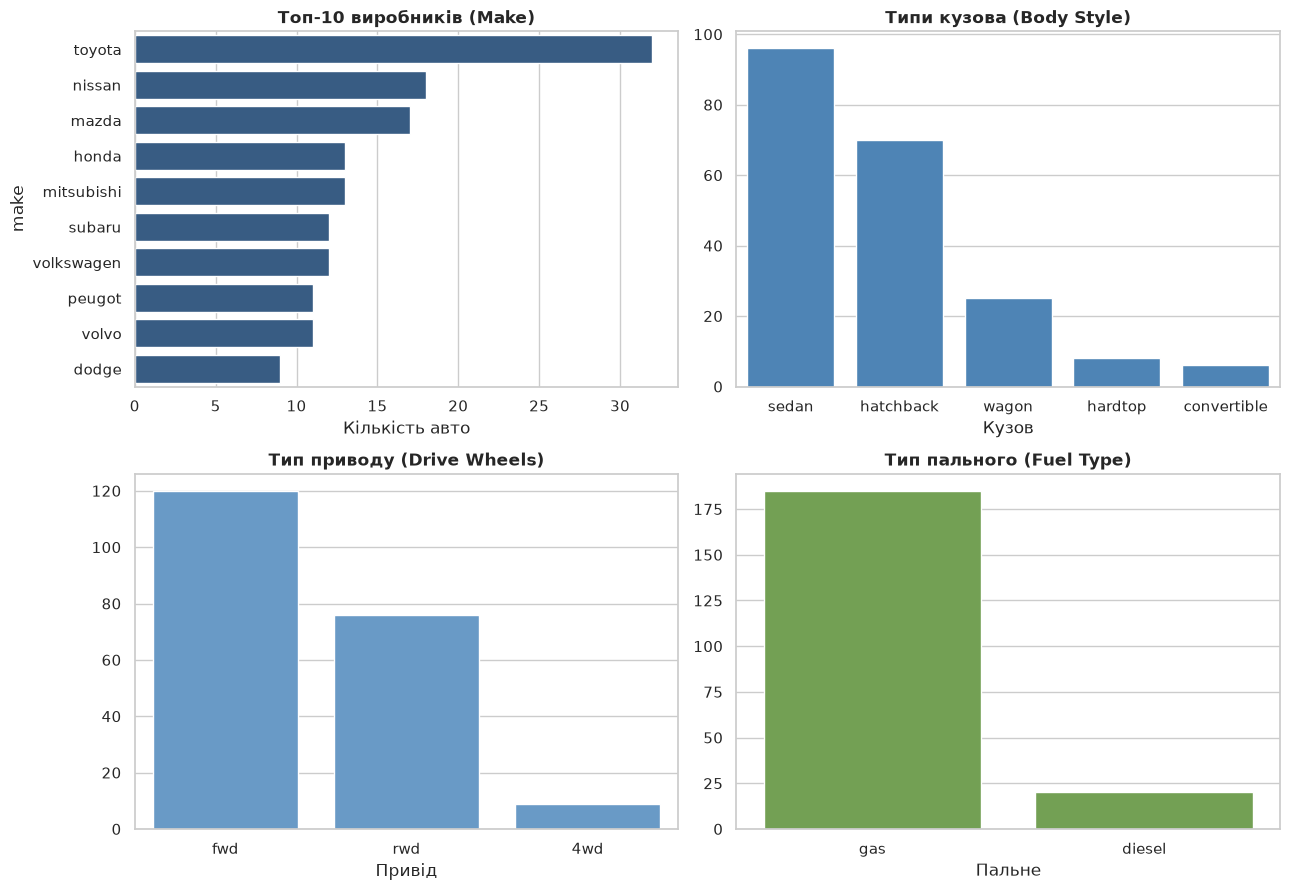

In [12]:
# Візуалізація частот для ключових категорійних ознак
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Топ-10 марок
top_makes = df["make"].value_counts().head(10)
sns.barplot(x=top_makes.values, y=top_makes.index, ax=axes[0, 0], color="#2b5c8f")
axes[0, 0].set_title("Топ-10 виробників (Make)", fontweight="bold")
axes[0, 0].set_xlabel("Кількість авто")

# Кузов
body_counts = df["body-style"].value_counts()
sns.barplot(x=body_counts.index, y=body_counts.values, ax=axes[0, 1], color="#3d85c6")
axes[0, 1].set_title("Типи кузова (Body Style)", fontweight="bold")
axes[0, 1].set_xlabel("Кузов")

# Привід
drive_counts = df["drive-wheels"].value_counts()
sns.barplot(x=drive_counts.index, y=drive_counts.values, ax=axes[1, 0], color="#5a9bd5")
axes[1, 0].set_title("Тип приводу (Drive Wheels)", fontweight="bold")
axes[1, 0].set_xlabel("Привід")

# Пальне
fuel_counts = df["fuel-type"].value_counts()
sns.barplot(x=fuel_counts.index, y=fuel_counts.values, ax=axes[1, 1], color="#70ad47")
axes[1, 1].set_title("Тип пального (Fuel Type)", fontweight="bold")
axes[1, 1].set_xlabel("Пальне")

plt.tight_layout()
plt.show()

**Висновки щодо категорійних ознак:**
- Більшість категорійних ознак (9 з 10) мають низьку кардинальність (`Low-cardinality`, $\le 8$ унікальних значень).
- `make` має помірну кардинальність (`Medium-cardinality`, 22 марки), де домінує бренд `toyota` (32 авто, 15.6%).
- Ознак типу `High-cardinality` або псевдо-ID у датасеті немає.
- Ринок характеризується переважанням бензинових авто (`gas` — 90.2%), переднього приводу (`fwd` — 58.5%) та кузова седан (`sedan` — 46.8%).

## 7. Дослідження розподілів числових ознак (Histograms + KDE)
Будуємо гістограми з ядерною оцінкою густини (KDE) та лініями середнього й медіани для аналізу форми розподілу, асиметрії та вершинності.

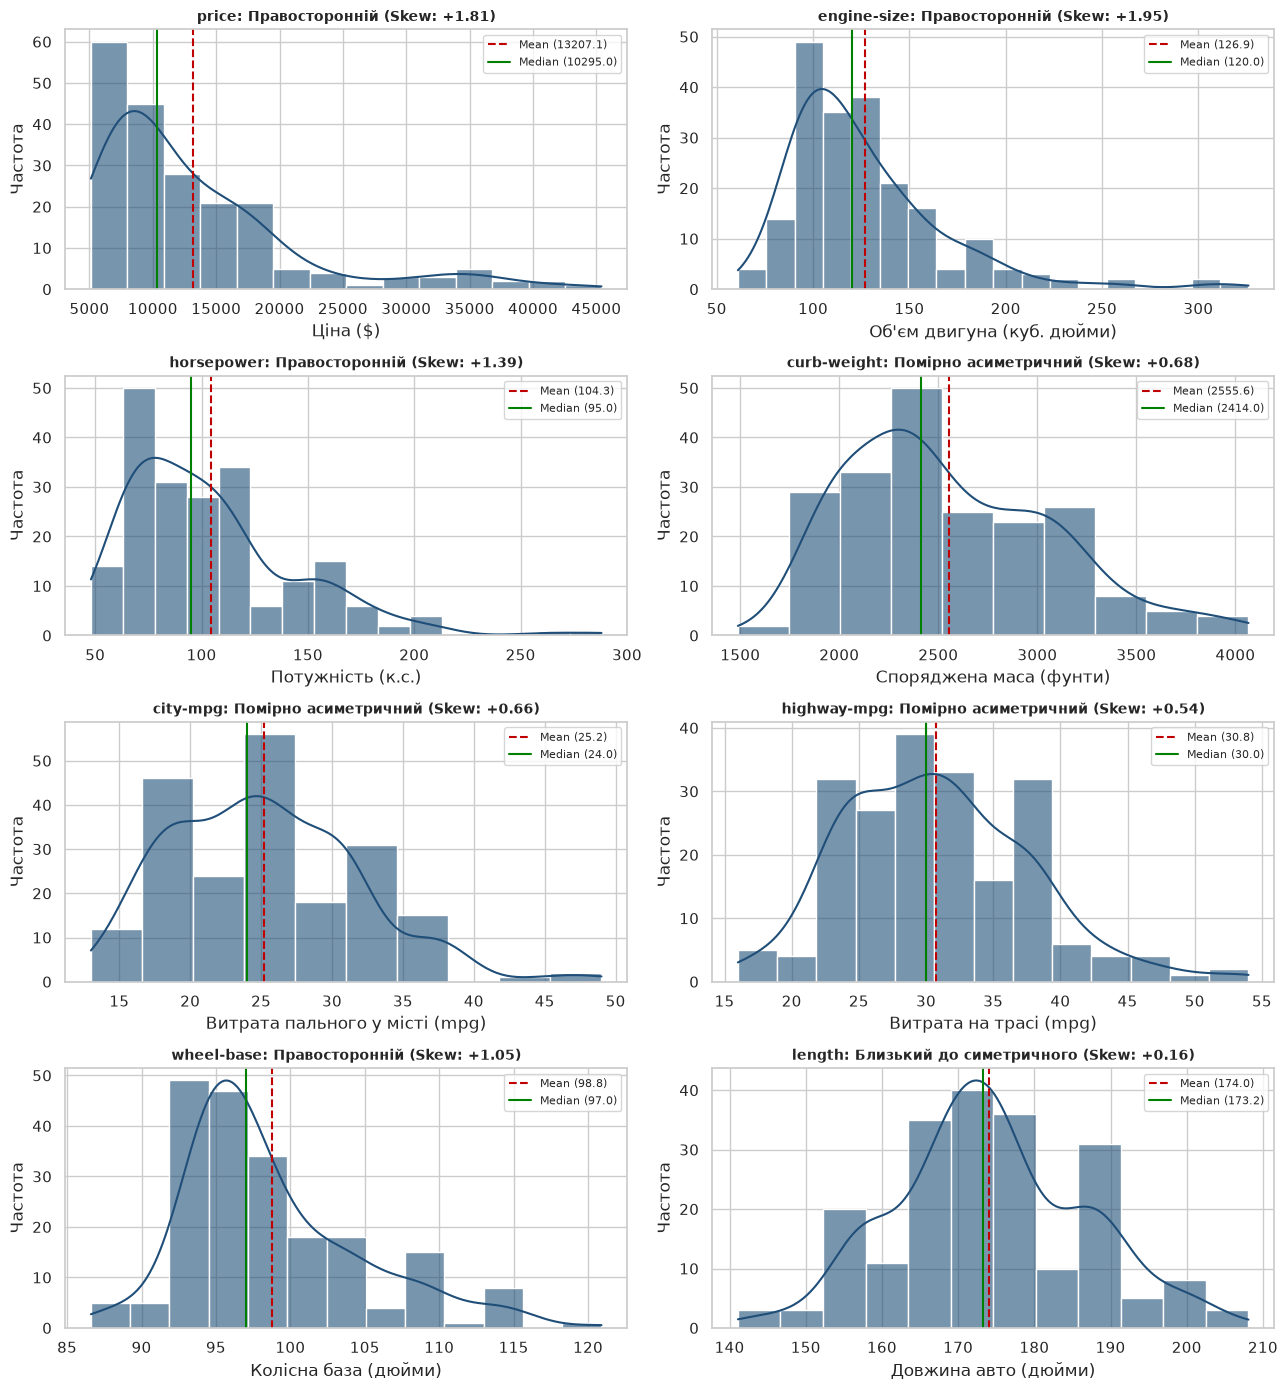

In [13]:
selected_hist_cols = [
    ("price", "Ціна ($)", "Правосторонній (Skew: +1.81)"),
    ("engine-size", "Об'єм двигуна (куб. дюйми)", "Правосторонній (Skew: +1.95)"),
    ("horsepower", "Потужність (к.с.)", "Правосторонній (Skew: +1.39)"),
    ("curb-weight", "Споряджена маса (фунти)", "Помірно асиметричний (Skew: +0.68)"),
    ("city-mpg", "Витрата пального у місті (mpg)", "Помірно асиметричний (Skew: +0.66)"),
    ("highway-mpg", "Витрата на трасі (mpg)", "Помірно асиметричний (Skew: +0.54)"),
    ("wheel-base", "Колісна база (дюйми)", "Правосторонній (Skew: +1.05)"),
    ("length", "Довжина авто (дюйми)", "Близький до симетричного (Skew: +0.16)")
]

fig, axes = plt.subplots(4, 2, figsize=(13, 14))
axes = axes.flatten()

for i, (col, xlabel, skew_info) in enumerate(selected_hist_cols):
    data = df[col].dropna()
    sns.histplot(data=data, kde=True, ax=axes[i], color="#1f4e78", edgecolor="white", alpha=0.6)
    axes[i].set_title(f"{col}: {skew_info}", fontweight="bold", fontsize=10)
    axes[i].set_xlabel(xlabel)
    axes[i].set_ylabel("Частота")
    
    mean_val = data.mean()
    median_val = data.median()
    axes[i].axvline(mean_val, color="#c00000", linestyle="--", linewidth=1.5, label=f"Mean ({mean_val:.1f})")
    axes[i].axvline(median_val, color="#008000", linestyle="-", linewidth=1.5, label=f"Median ({median_val:.1f})")
    axes[i].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

**Характеристика розподілів:**
- `price`, `engine-size`, `horsepower`: одновершинні з високою концентрацією в бюджетному сегменті та вираженим довгим правим хвостом (Heavy Right Tail).
- `curb-weight`, `city-mpg`, `highway-mpg`: одновершинні, помірно асиметричні зі зсувом у бік економічних авто.
- `length`: одновершинний, практично симетричний розподіл.
- `compression-ratio`: виражено бімодальний (два кластери: бензинові двигуни 8–10 та дизельні 21–23).

## 8. Перевірка числових даних на нормальний розподіл
Формулюємо статистичні гіпотези:
- **$H_0$:** вибірка походить з генеральної сукупності з нормальним розподілом.
- **$H_1$:** розподіл ознаки статистично значуще відрізняється від нормального.
Рівень значущості: $\alpha = 0.05$. Використовуємо тест Шапіро–Вілка (`scipy.stats.shapiro`).

In [14]:
norm_results = []

for col in numeric_columns:
    data = df[col].dropna()
    stat, p_val = stats.shapiro(data)
    conclusion = "Відхиляємо H0 (не нормальний)" if p_val < 0.05 else "Приймаємо H0 (нормальний)"
    
    norm_results.append({
        'Feature': col,
        'Skewness': data.skew(),
        'Shapiro Stat (W)': stat,
        'p-value': f"{p_val:.2e}" if p_val < 0.001 else f"{p_val:.4f}",
        'Conclusion (alpha=0.05)': conclusion
    })

pd.DataFrame(norm_results)

,Feature,Skewness,Shapiro Stat (W),p-value,Conclusion (alpha=0.05)
0,symboling,0.21,0.92,2.52e-09,Відхиляємо H0 (не нормальний)
1,normalized-losses,0.77,0.95,1.11e-05,Відхиляємо H0 (не нормальний)
2,wheel-base,1.05,0.91,1.04e-09,Відхиляємо H0 (не нормальний)
3,length,0.16,0.98,0.0104,Відхиляємо H0 (не нормальний)
4,width,0.90,0.92,5.01e-09,Відхиляємо H0 (не нормальний)
5,height,0.06,0.98,0.0217,Відхиляємо H0 (не нормальний)
6,curb-weight,0.68,0.95,2.89e-06,Відхиляємо H0 (не нормальний)
7,engine-size,1.95,0.83,3.06e-14,Відхиляємо H0 (не нормальний)
8,bore,0.02,0.96,5.49e-05,Відхиляємо H0 (не нормальний)
9,stroke,-0.68,0.94,1.84e-07,Відхиляємо H0 (не нормальний)


**Інтерпретація результатів тестування нормальності:**
Для всіх 16 числових ознак розраховане значення $p$-value є значно меншим за поріг $\alpha = 0.05$. Відповідно, нульова гіпотеза $H_0$ про нормальність розподілу відхиляється для всіх ознак.  
Навіть для параметрів із мінімальним скіунессом (`height`, `length`) тест Шапіро–Вілка фіксує відхилення від ідеальної кривої Гаусса через дискретність кроків вимірювання та відхилення у квантилях хвостів.

## 9. Побудова квантильних діаграм (Q-Q Plots)
Візуально досліджуємо наближення вибіркових квантилів до теоретичного нормального розподілу для 6 ключових параметрів.

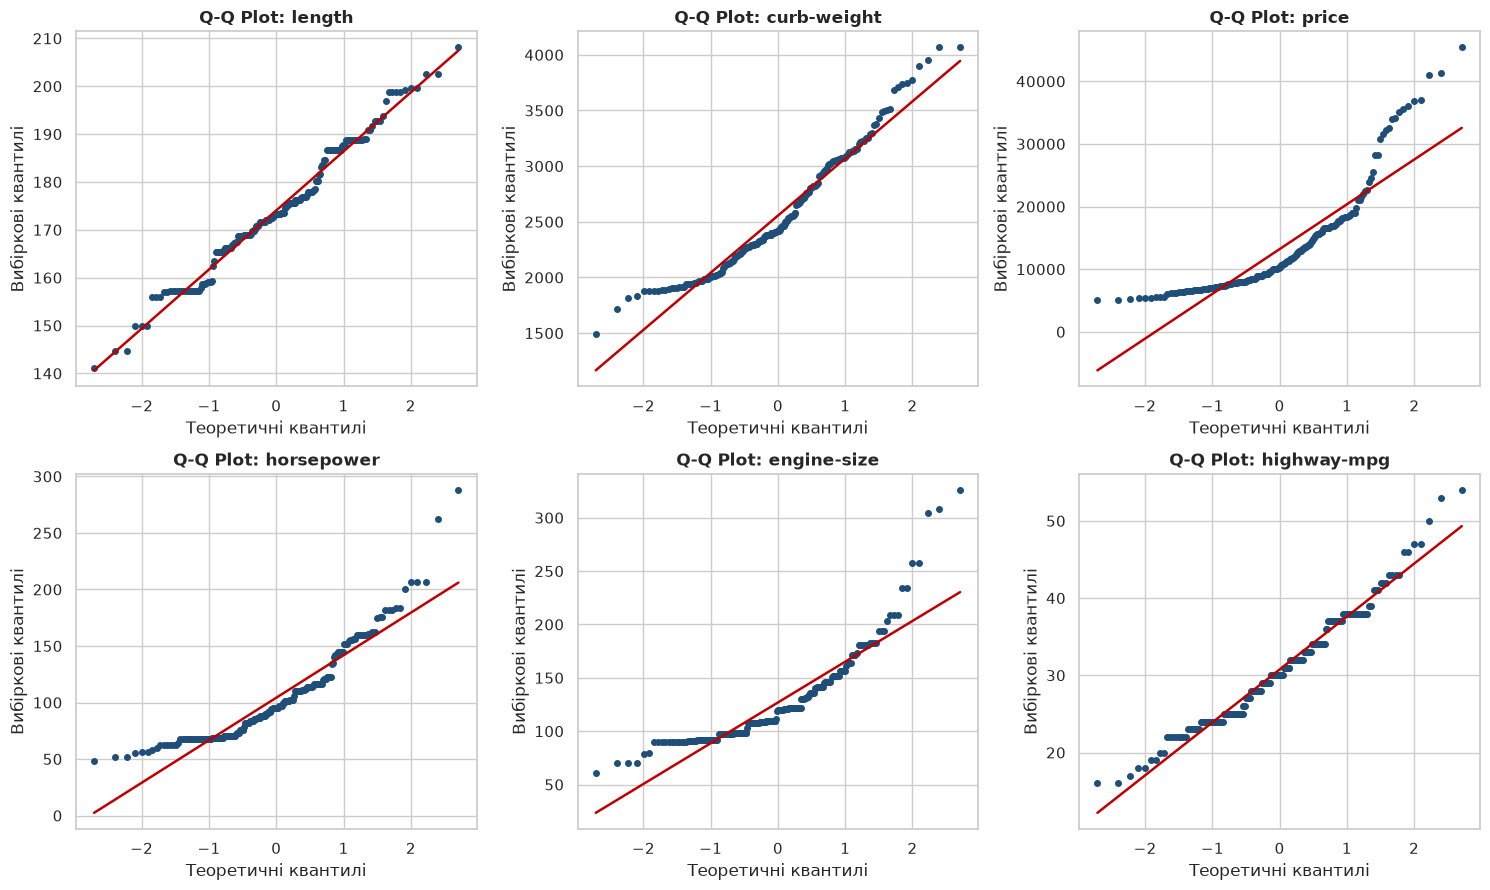

In [15]:
selected_qq_cols = ["length", "curb-weight", "price", "horsepower", "engine-size", "highway-mpg"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(selected_qq_cols):
    data = df[col].dropna()
    stats.probplot(data, dist="norm", plot=axes[i])
    axes[i].get_lines()[0].set_color("#1f4e78")
    axes[i].get_lines()[0].set_markersize(4)
    axes[i].get_lines()[1].set_color("#c00000")
    axes[i].get_lines()[1].set_linewidth(1.8)
    axes[i].set_title(f"Q-Q Plot: {col}", fontweight="bold")
    axes[i].set_xlabel("Теоретичні квантилі")
    axes[i].set_ylabel("Вибіркові квантилі")

plt.tight_layout()
plt.show()

**Аналіз Q-Q Plots:**
- Для `length` та `curb-weight` центральні точки розташовані близько до опорної лінії, проте на краях (нижній і верхній хвости) спостерігаються відхилення.
- Для `price`, `horsepower` та `engine-size` виявляється виражений вигин угору в зоні позитивних квантилів ($z > 1.5$), що підтверджує наявність довгого важкого правого хвоста та значної позитивної асиметрії.

## 10. Аналіз викидів (Outlier Analysis)
Будуємо діаграми розмаху (Boxplot) та застосовуємо міжквартильний розмах (IQR за правилом Тьюкі) для числового визначення кількості й частки викидів.

In [16]:
outliers_data = []

for col in numeric_columns:
    data = df[col].dropna()
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    outliers_data.append({
        'Feature': col,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outliers Count': len(outliers),
        'Outliers Pct': len(outliers) / len(data) * 100
    })

outliers_df = pd.DataFrame(outliers_data).sort_values(by='Outliers Pct', ascending=False)
outliers_df

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers Count,Outliers Pct
10,compression-ratio,8.60,9.40,0.80,7.40,10.60,28,13.66
9,stroke,3.11,3.41,0.30,2.66,3.86,20,9.95
15,price,7775.00,16500.00,8725.00,-5312.50,29587.50,14,6.97
7,engine-size,97.00,141.00,44.00,31.00,207.00,10,4.88
4,width,64.10,66.90,2.80,59.90,71.10,8,3.90
11,horsepower,70.00,116.00,46.00,1.00,185.00,6,2.96
2,wheel-base,94.50,102.40,7.90,82.65,114.25,3,1.46
14,highway-mpg,25.00,34.00,9.00,11.50,47.50,3,1.46
12,peak-rpm,4800.00,5500.00,700.00,3750.00,6550.00,2,0.99
13,city-mpg,19.00,30.00,11.00,2.50,46.50,2,0.98


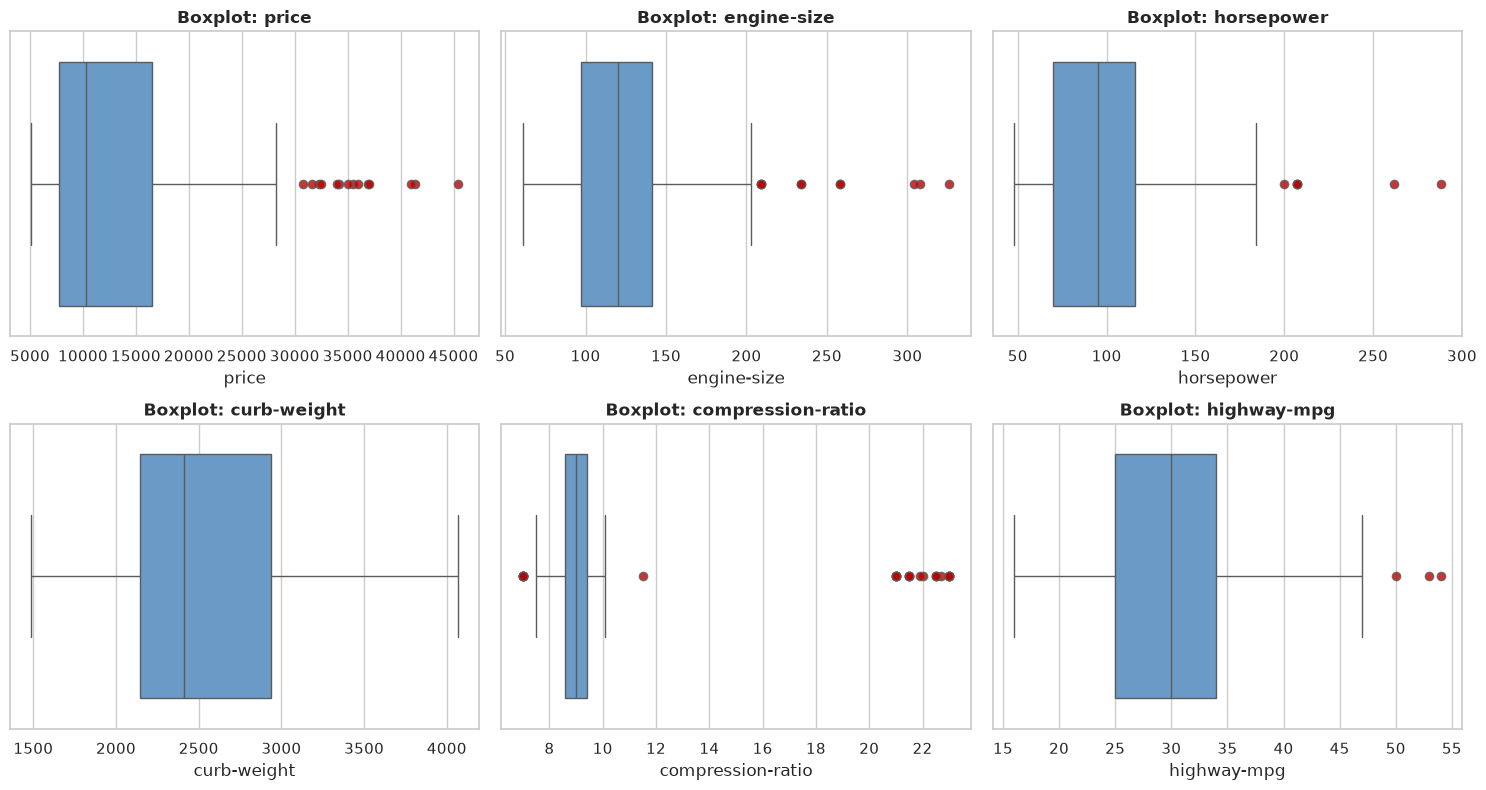

In [17]:
# Boxplots для ключових ознак з викидами
outlier_features = ["price", "engine-size", "horsepower", "curb-weight", "compression-ratio", "highway-mpg"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(outlier_features):
    data = df[col].dropna()
    sns.boxplot(x=data, ax=axes[i], color="#5b9bd5", flierprops=dict(marker="o", markersize=6, markerfacecolor="#c00000", alpha=0.8))
    axes[i].set_title(f"Boxplot: {col}", fontweight="bold")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

**Аналіз природи викидів для топ-3 ознак:**
1. `compression-ratio` (28 викидів, 13.66%): значення від 21.0 до 23.0. Це **не помилка**, а фізична властивість дизельних двигунів (20 спостережень у вибірці). Дизельні двигуни працюють за принципом займання від стиснення, тому їх ступінь стиснення принципово вищий за бензинові (8.0–10.0).
2. `stroke` (20 викидів, 9.95%): значення поза типовим діапазоном 2.66–3.86. Це специфічні короткохідні або довгохідні модифікації моторів окремих виробників.
3. `price` (14 викидів, 6.97%): ціни вище $29,587 (аж до $45,400). Це **реальні екстремальні спостереження** преміум-сегменту автомобілів (Mercedes-Benz, Porsche, BMW, Jaguar). Видаляти їх не можна, проте для лінійних алгоритмів варто застосувати логарифмічне перетворення `np.log1p(price)`.

## 11. Кореляційний аналіз
Будуємо матрицю парної лінійної кореляції Пірсона та візуалізуємо її у вигляді теплової карти (Heatmap).

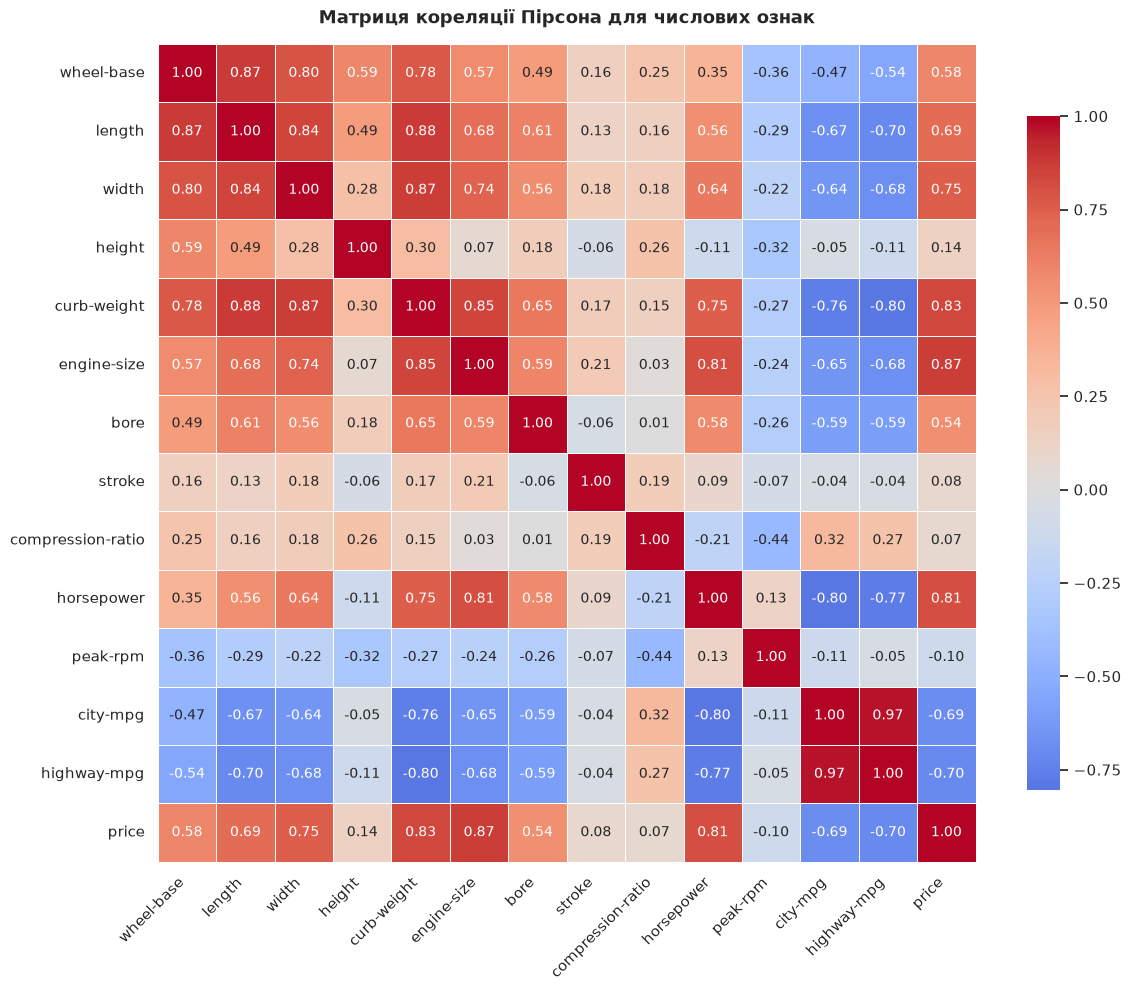

In [18]:
corr_cols = [
    "wheel-base", "length", "width", "height", "curb-weight",
    "engine-size", "bore", "stroke", "compression-ratio",
    "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price"
]
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Матриця кореляції Пірсона для числових ознак", fontsize=13, fontweight="bold", pad=15)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [19]:
# Пошук екстремальних пар кореляцій
pairs = []
for i in range(len(corr_cols)):
    for j in range(i+1, len(corr_cols)):
        c1, c2 = corr_cols[i], corr_cols[j]
        pairs.append((c1, c2, corr_matrix.loc[c1, c2]))

pairs_sorted = sorted(pairs, key=lambda x: x[2], reverse=True)

print("Топ-3 найсильніші додатні кореляції:")
for c1, c2, r in pairs_sorted[:3]:
    print(f" - {c1} & {c2}: r = {r:.4f}")

print("\nТоп-3 найсильніші від'ємні кореляції:")
for c1, c2, r in pairs_sorted[-3:]:
    print(f" - {c1} & {c2}: r = {r:.4f}")

print("\nОзнаки із найслабшою кореляцією (|r| < 0.05):")
for c1, c2, r in sorted([p for p in pairs if abs(p[2]) < 0.05], key=lambda x: abs(x[2])):
    print(f" - {c1} & {c2}: r = {r:.4f}")

Топ-3 найсильніші додатні кореляції:
 - city-mpg & highway-mpg: r = 0.9713
 - length & curb-weight: r = 0.8777
 - wheel-base & length: r = 0.8746

Топ-3 найсильніші від'ємні кореляції:
 - horsepower & highway-mpg: r = -0.7709
 - curb-weight & highway-mpg: r = -0.7975
 - horsepower & city-mpg: r = -0.8036

Ознаки із найслабшою кореляцією (|r| < 0.05):
 - bore & compression-ratio: r = 0.0052
 - engine-size & compression-ratio: r = 0.0290
 - stroke & city-mpg: r = -0.0429
 - stroke & highway-mpg: r = -0.0445
 - height & city-mpg: r = -0.0486


**Теоретичне питання:** *Чи завжди низьке значення коефіцієнта кореляції означає відсутність залежності між ознаками?*  
**Відповідь:** Ні. Коефіцієнт лінійної кореляції Пірсона вимірює виключно ступінь **лінійного зв'язку**. Якщо між ознаками існує нелінійна залежність (квадратична, експоненційна, синусоїдальна або кластерна), коефіцієнт Пірсона може бути близьким до нуля при наявності суворої функціональної залежності.

## 12. Матриця розсіювання (Scatter Plot Matrix)
Побудова парних діаграм розсіювання для дослідження взаємозв'язків між ціною, об'ємом двигуна, потужністю, масою та витратою пального з диференціацією за типом приводу.

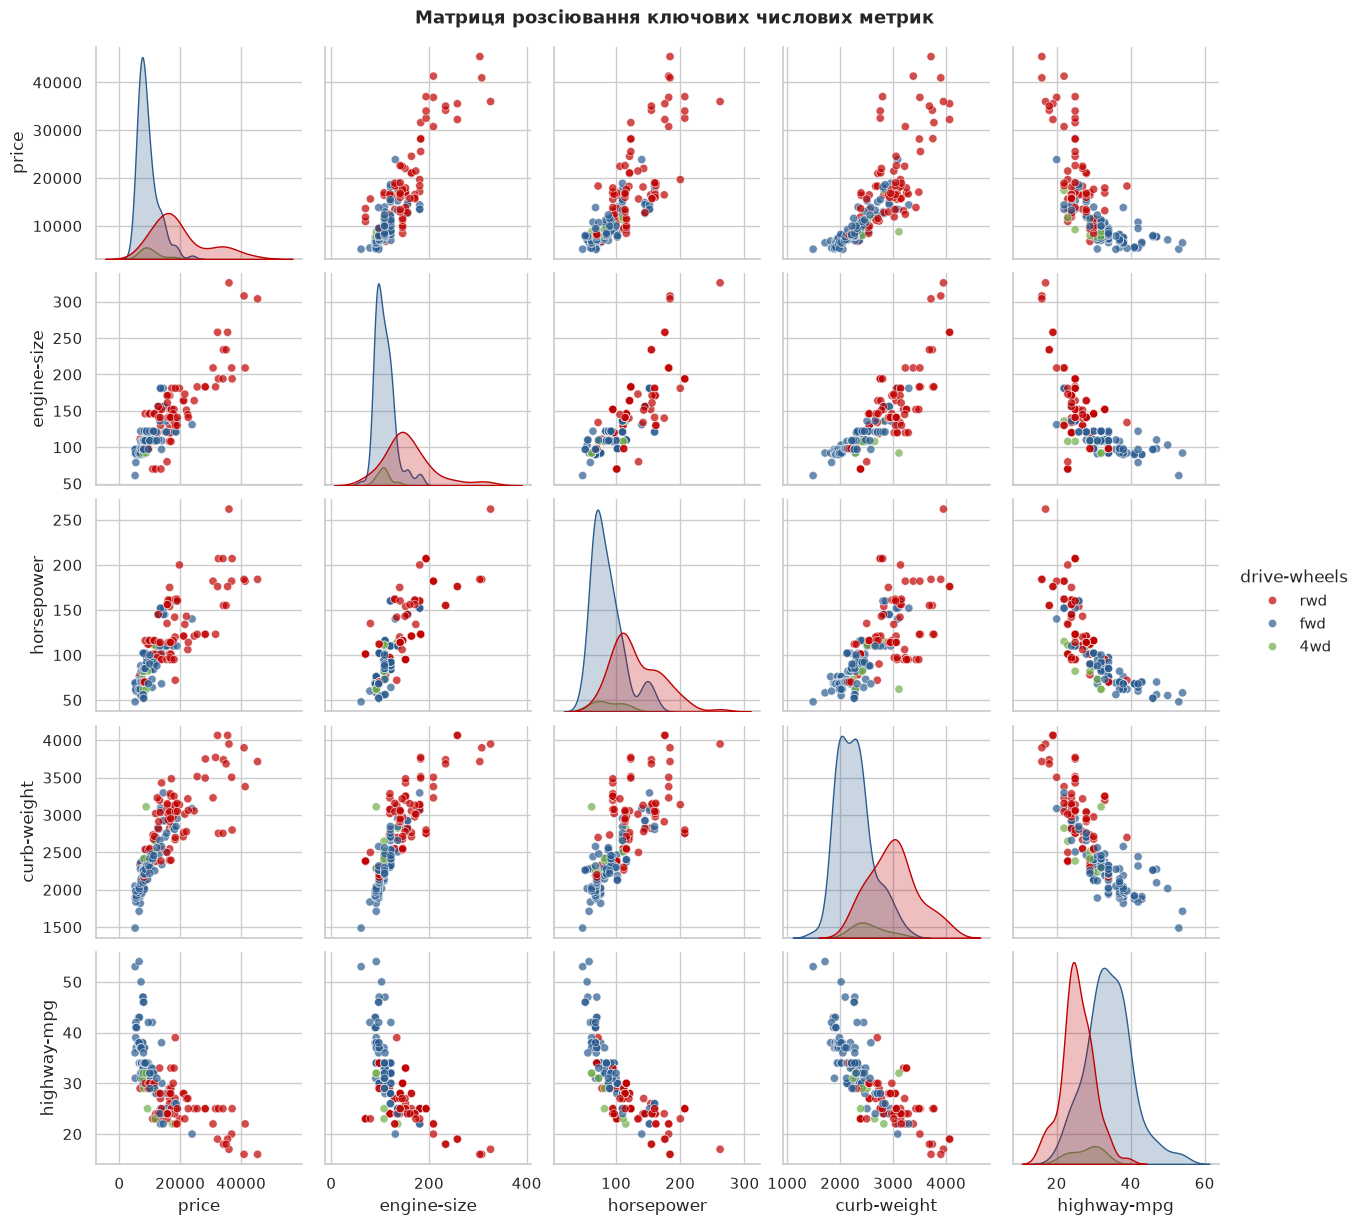

In [20]:
pair_cols = ["price", "engine-size", "horsepower", "curb-weight", "highway-mpg", "drive-wheels"]
pair_df = df[pair_cols].dropna()

pair_grid = sns.pairplot(
    pair_df,
    hue="drive-wheels",
    palette={"fwd": "#2b5c8f", "rwd": "#c00000", "4wd": "#70ad47"},
    diag_kind="kde",
    plot_kws={"alpha": 0.7, "s": 35}
)
pair_grid.figure.subplots_adjust(top=0.95)
pair_grid.figure.suptitle("Матриця розсіювання ключових числових метрик", fontsize=13, fontweight="bold")
plt.show()

**Три виявлені нетривіальні закономірності:**
1. **Нелінійний закон витрати пального:** Зв'язок між спорядженою масою (`curb-weight`) та витратою (`highway-mpg`) має вигляд гіперболи $y \sim 1/x$. Збільшення маси в діапазоні 1500–2500 фунтів призводить до стрімкого падіння показника mpg, але після 3000 фунтів крива виположується.
2. **Сегрегація кластерів за типом приводу:** Передньопривідні машини (`fwd`) сконцентровані в компактному кластері низької ціни ($< 12,000), малого об'єму двигуна та високої паливної ефективності. Задньопривідні (`rwd`) утворюють витягнутий високоваріативний кластер підвищеної ціни та потужності.
3. **Експоненційне зростання ціни від потужності:** Залежність `price` від `horsepower` та `engine-size` демонструє розшарування. Для масових авто приріст потужності дає помірне здорожчання, проте для показників $> 140$ к.с. вартість стрімко зростає вгору.

## 13. Аналіз «числова ознака — категорійна ознака»
Досліджуємо взаємозв'язок між категорійними параметрами (`drive-wheels`, `body-style`) та числовими метриками (`price`, `horsepower`) за допомогою групування та діаграм boxplot.

In [21]:
print("=== Згрупована статистика: Drive Wheels vs Price ===")
display(df.groupby('drive-wheels', observed=True)['price'].agg(['count', 'mean', 'median', 'std']))

print("\n=== Згрупована статистика: Drive Wheels vs Horsepower ===")
display(df.groupby('drive-wheels', observed=True)['horsepower'].agg(['count', 'mean', 'median', 'std']))

print("\n=== Згрупована статистика: Body Style vs Price ===")
display(df.groupby('body-style', observed=True)['price'].agg(['count', 'mean', 'median', 'std']))

print("\n=== Згрупована статистика: Body Style vs Horsepower ===")
display(df.groupby('body-style', observed=True)['horsepower'].agg(['count', 'mean', 'median', 'std']))

=== Згрупована статистика: Drive Wheels vs Price ===


,count,mean,median,std
drive-wheels,,,,
4wd,8,10241.00,9005.50,3288.21
fwd,118,9244.78,8192.00,3345.90
rwd,75,19757.61,16900.00,9082.58



=== Згрупована статистика: Drive Wheels vs Horsepower ===


,count,mean,median,std
drive-wheels,,,,
4wd,9,95.33,82.00,31.89
fwd,118,85.97,82.00,25.09
rwd,76,133.70,120.50,41.76



=== Згрупована статистика: Body Style vs Price ===


,count,mean,median,std
body-style,,,,
convertible,6,21890.50,17084.50,11187.80
hardtop,8,22208.50,19687.50,14555.52
hatchback,68,9957.44,8672.00,4148.86
sedan,94,14459.76,11078.50,8523.21
wagon,25,12371.96,11694.00,5120.95



=== Згрупована статистика: Body Style vs Horsepower ===


,count,mean,median,std
body-style,,,,
convertible,6,131.67,113.50,42.56
hardtop,8,142.25,119.50,50.61
hatchback,69,101.33,88.00,42.68
sedan,96,103.10,96.00,37.16
wagon,24,97.75,94.50,28.54


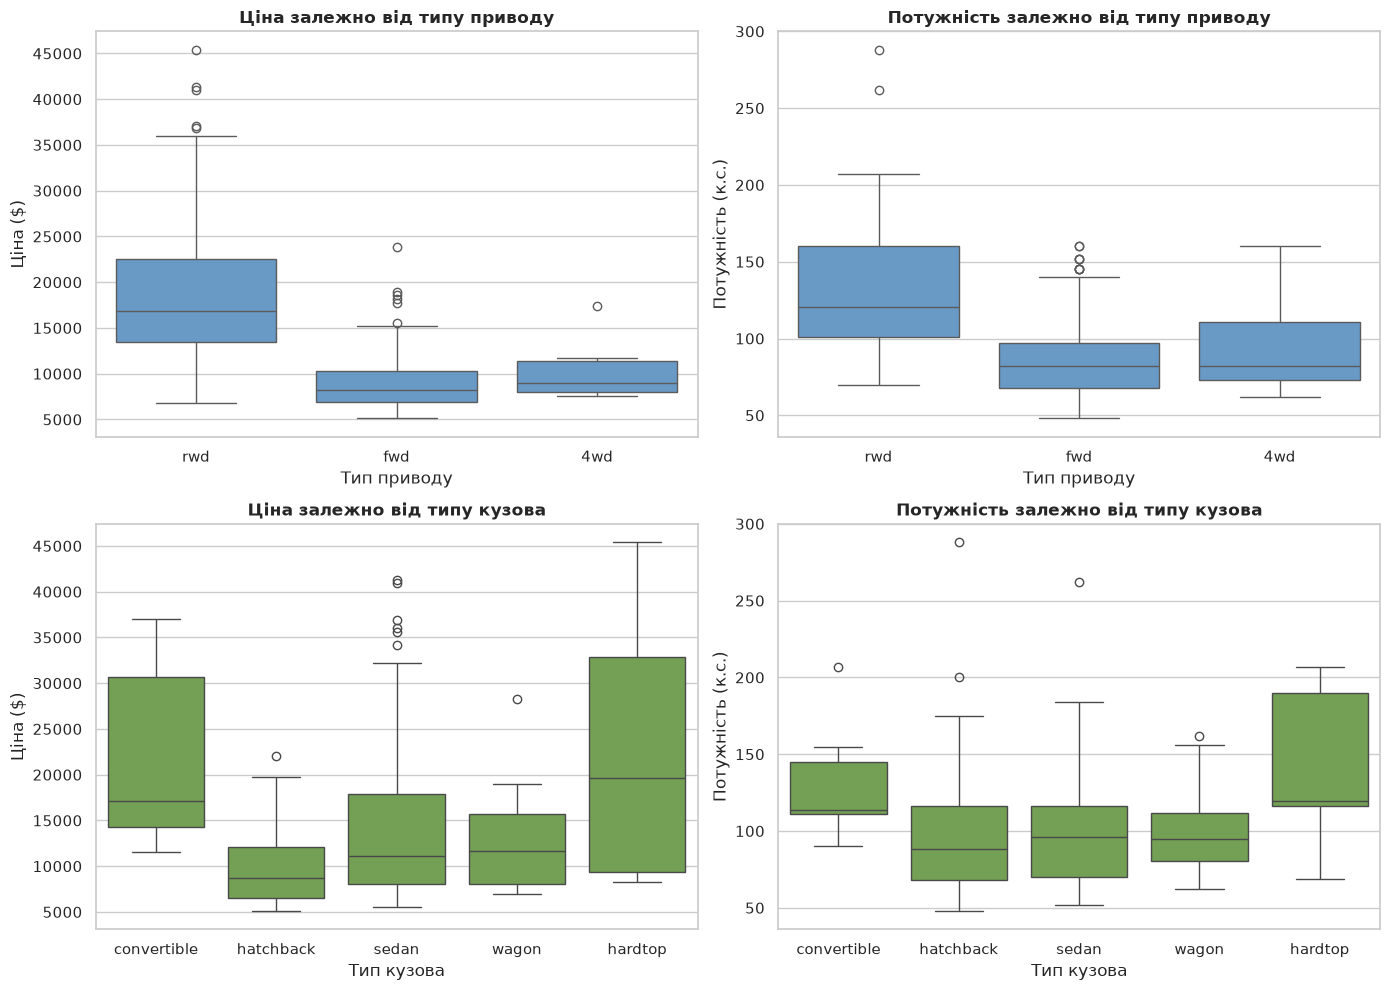

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=df, x="drive-wheels", y="price", ax=axes[0, 0], color="#5a9bd5")
axes[0, 0].set_title("Ціна залежно від типу приводу", fontweight="bold")
axes[0, 0].set_xlabel("Тип приводу")
axes[0, 0].set_ylabel("Ціна ($)")

sns.boxplot(data=df, x="drive-wheels", y="horsepower", ax=axes[0, 1], color="#5a9bd5")
axes[0, 1].set_title("Потужність залежно від типу приводу", fontweight="bold")
axes[0, 1].set_xlabel("Тип приводу")
axes[0, 1].set_ylabel("Потужність (к.с.)")

sns.boxplot(data=df, x="body-style", y="price", ax=axes[1, 0], color="#70ad47")
axes[1, 0].set_title("Ціна залежно від типу кузова", fontweight="bold")
axes[1, 0].set_xlabel("Тип кузова")
axes[1, 0].set_ylabel("Ціна ($)")

sns.boxplot(data=df, x="body-style", y="horsepower", ax=axes[1, 1], color="#70ad47")
axes[1, 1].set_title("Потужність залежно від типу кузова", fontweight="bold")
axes[1, 1].set_xlabel("Тип кузова")
axes[1, 1].set_ylabel("Потужність (к.с.)")

plt.tight_layout()
plt.show()

**Висновки порівняльного аналізу:**
- Задньопривідні автомобілі (`rwd`) істотно дорожчі (середня ціна $19,758, медіана $16,900) та потужніші (133.7 к.с.) за передньопривідні (`fwd`, середня ціна $9,245, медіана $8,192). Розкид цін у групі `rwd` втричі більший (std = $9,083 проти $3,346).
- Серед типів кузова преміальними виступають `hardtop` ($22,208) та `convertible` ($21,890), тоді як `hatchback` є найбільш бюджетним сегментом (медіана $8,672).

## 14. Підсумковий аналіз результатів (Відповіді на контрольні запитання)

1. **Яку структуру має досліджуваний набір даних?**  
   Датасет містить 205 рядків та 26 колонок (16 потенційно числових характеристик та 10 категорійних ознак). Ознаки дати/часу та технічні ID-колонки відсутні.
2. **Які проблеми якості даних було виявлено?**  
   Виявлено використання символу `'?'` замість стандартних пропусків `NaN`, невідповідність типів даних (`object` замість числових для 6 колонок), а також пропуски у категорійній ознаці `num-of-doors`.
3. **Які ознаки містять найбільшу кількість пропущених значень?**  
   `normalized-losses` містить найбільше пропусків — 41 (20.00%). Також пропуски є в `price` (4), `bore` (4), `stroke` (4), `horsepower` (2), `peak-rpm` (2), `num-of-doors` (2).
4. **Які числові ознаки мають приблизно симетричний розподіл?**  
   `height` (skew = +0.06), `length` (skew = +0.16) та `bore` (skew = +0.02).
5. **Які характеризуються значною асиметрією?**  
   `compression-ratio` (skew = +2.61), `engine-size` (skew = +1.95), `price` (skew = +1.81), `horsepower` (skew = +1.39) та `wheel-base` (skew = +1.05).
6. **Для яких ознак статистичні тести не дають підстав відхилити гіпотезу про нормальність?**  
   Для жодної. Тест Шапіро–Вілка дав $p < 0.05$ для всіх 16 числових ознак, відхиливши $H_0$.
7. **Які ознаки містять найбільшу кількість потенційних викидів?**  
   `compression-ratio` (28 викидів, 13.66%), `stroke` (20 викидів, 9.95%), `price` (14 викидів, 6.97%) та `engine-size` (10 викидів, 4.88%).
8. **Які категорійні ознаки характеризуються високою cardinality?**  
   Ознак із високою кардинальністю немає. Найвищу серед категорійних має `make` (22 марки, помірна кардинальність).
9. **Між якими числовими ознаками спостерігається найбільша кореляція?**  
   Додатна: `city-mpg` та `highway-mpg` ($r = 0.9713$), `length` та `curb-weight` ($r = 0.8777$), `engine-size` та `price` ($r = 0.8723$).  
   Від'ємна: `horsepower` та `city-mpg` ($r = -0.8036$), `curb-weight` та `highway-mpg` ($r = -0.7975$).
10. **Які додаткові закономірності виявлено за допомогою матриці розсіювання?**  
    Нелінійний (гіперболічний) характер падіння паливної ефективності від ваги авто, чітка кластеризація за типом приводу (`fwd` vs `rwd`) та експоненційне зростання цін у спорткарах.
11. **Які проблеми можуть вплинути на подальше застосування алгоритмів машинного навчання?**  
    Мультиколінеарність між габаритами й вагою авто ($r > 0.87$), сильна правостороння асиметрія ціни та потужності, чутливість до викидів та наявність 20% пропусків у `normalized-losses`.
12. **Які операції підготовки даних необхідно включити до наступного Data Engineering pipeline?**  
    - Видалення 4 рядків із пропущеною цільовою змінною `price`.
    - Групова імпутація медіаною для `normalized-losses`, `bore`, `stroke`, `horsepower`, `peak-rpm`.
    - Імпутація модою для `num-of-doors`.
    - One-Hot Encoding для номінальних ознак (`fuel-type`, `body-style`, `drive-wheels`).
    - Логарифмічна трансформація (`log1p`) ціни та об'єму двигуна для усунення асиметрії.
    - Робастне масштабування (`RobustScaler` або `StandardScaler`).